## Figuras Iterativas

In [1]:
%matplotlib widget

In [3]:
import sys, subprocess

repo_path = r"C:\Users\Theodoro\OneDrive\Documentos\Caos\caos_functions"

r = subprocess.run(
    [sys.executable, "dop853cpp/setup.py", "build_ext", "--inplace"],
    cwd=repo_path,
    capture_output=True,
    text=True,
)
print(r.stdout[-3000:])
print(r.stderr[-3000:])

running build_ext
building 'rossler_cpp' extension
"C:\Program Files (x86)\Microsoft Visual Studio\18\BuildTools\VC\Tools\MSVC\14.51.36231\bin\HostX86\x64\cl.exe" /c /nologo /O2 /W3 /GL /DNDEBUG /MD -IC:\Users\Theodoro\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pybind11\include "-IC:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\include" "-IC:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Include" "-IC:\Program Files (x86)\Microsoft Visual Studio\18\BuildTools\VC\Tools\MSVC\14.51.36231\include" "-IC:\Program Files (x86)\Microsoft Visual Studio\18\BuildTools\VC\Auxiliary\VS\include" "-IC:\Program Files (x86)\Windows Kits\10\include\10.0.26100.0\ucrt" "-IC:\Program Files (x86)\Windows Kits\10\\include\10.0.26100.0\\um" "-IC:\Program Files (x86)\Windows Kits\10\\include\10.0.26100.0\\shared" "-IC:\Program Files (x8

In [4]:
import sys, subprocess, os

repo_path = r"C:\Users\Theodoro\OneDrive\Documentos\Caos\caos_functions"

subprocess.run([sys.executable, "-m", "pip", "install", "pybind11"], check=True)
subprocess.run(
    [sys.executable, "dop853cpp/setup.py", "build_ext", "--inplace"],
    cwd=repo_path,
    check=True,
)

CompletedProcess(args=['C:\\Users\\Theodoro\\AppData\\Local\\Microsoft\\WindowsApps\\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\\python.exe', 'dop853cpp/setup.py', 'build_ext', '--inplace'], returncode=0)

# Simulação e Diagrama de Bifurcação do Sistema de rossler para cs variados usando integração com C++

### O módulo para a interface entre o Python e o C++ já foi criado e o código compilado na pasta "caos_functions" de forma que o notebook "rossler" consegue, localmente, fazer a integração do sistema em C++

#### Primeiro, os imports necessários e setando o caminho para a pasta das funções, dentro da pasta atual

In [1]:







# Estando montado localmente


import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline

%cd caos_functions/

from rossler import simulaRosslerCPP

c:\Users\Theodoro\OneDrive\Documentos\Caos\caos_functions


In [2]:

  # Configurações usadas para a maioria das simulações. Só não é utilizada para o cáluclo do maior Lyapunov pro caso caótico, em que é necessário um atol e rtol menores.

options = dict(atol=1e-10, rtol=1e-7, dense_output=False, method='DOP853')
np.random.seed(15489998) #nUSP para random seed


  # define o sistema de Rossler, para ser utilizado na função que o simula
def rosslerMapa(t, r, a =0.1, b=0.1, c=11.):
  x, y, z = r
  return np.array([
       (-y - z),
      x + a*y,
      b + (x - c) * z
      ])


  # define o evento de X máximo
def eventoXMaximo(t, r, a =0.1, b=0.1, c=11.):
    return rosslerMapa(t,r,a=a, b=b, c=c)[0]
eventoXMaximo.direction = -1


  # Função que simula o sistema de Rossler, a partir do solve_ivp. Configurações de transiente já são especificados nos parametros
  # Já é feito também uma segunda trajetória, para ser usada no cálculo do Lyapunov. A distância (dist0), após o transiente, é parâmetro
def simularosslerIVP(a =0.1, b=0.1, c=11., tTransiente=100, tSpan=10_000, nMax=500, r0=None, options=options, dist0=1e-5):
  eventoXMaximo.terminal = nMax
  if r0 is None:
    r0 = np.random.randn(3)
  solTransiente = solve_ivp(rosslerMapa, y0=r0, t_span=[0, tTransiente], args=(a,b,c,), **options)
  r1 = solTransiente.y[:,-1]
  sol = solve_ivp(rosslerMapa, y0=r1, t_span=[0, tSpan], events=eventoXMaximo, args=(a,b,c,), **options)


  rF = sol.y[:,-1]
  max = sol.y_events[0]

  
  u = np.random.randn(3)
  dr = dist0 * u/np.sqrt(np.sum(u**2))
  sollinha = solve_ivp(rosslerMapa, y0=r1+dr, t_span=[0, tSpan], events=eventoXMaximo, args=(a,b,c,), **options)

  return rF, max, sol, sollinha

# retorna a posição final, o array dos X_maximos e, mais importante, os arrays da trajetória r (argumento [2]) e rlinha (argumento [3])

# Exercícios

## a)


#### Séries temporais e figura 3d do atrator no caso de caótico

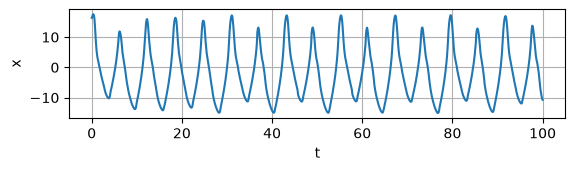

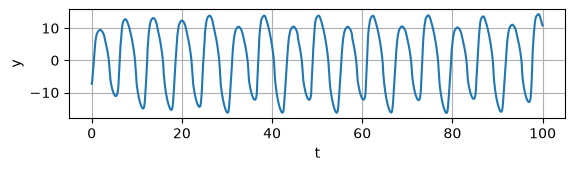

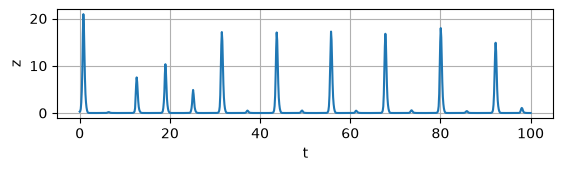

In [3]:
# Séries temporais

r0 = np.random.randn(3) # r0 randomizado
NOMEs = ['x', 'y', 'z']
t_span = [0,100]
c = 11.0

#simulação de com t_span de 100 e transiente de 1_000
Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=1_000, tSpan=100, nMax=500, r0=r0, options=options)
r = Sol[2].y

t = np.linspace( 0, t_span[-1], r.shape[1]) # acertando o tamanho do array temporal para a plotagem

for i in range(3):
  plt.figure()
  plt.subplot(3,1,i+1)
  plt.plot( t, r[i] )
  plt.grid()
  plt.ylabel( NOMEs[i] )
  plt.xlabel( 't' )
  plt.show()

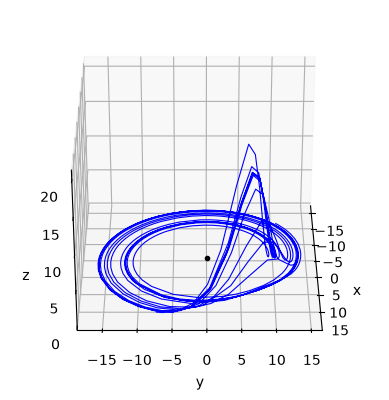

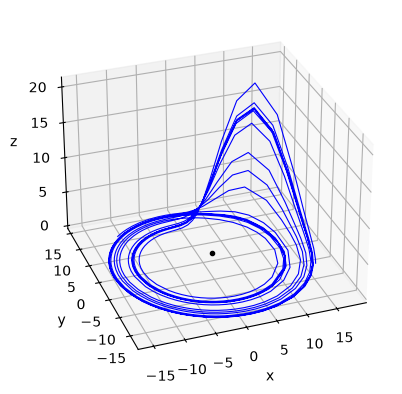

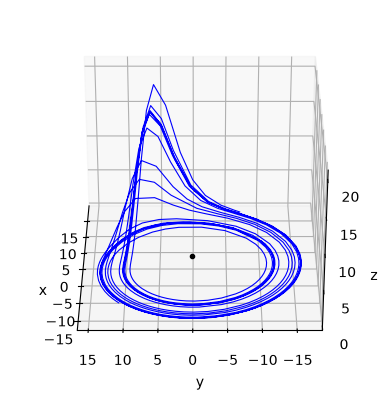

In [4]:

for azim in [0,250,180]: # angulos para a visualização do atrator caótico
    plt.figure()
    ax3d = plt.gcf().add_subplot( projection='3d' ) # plotagem 3d
    ax3d.plot( r[0], r[1], r[2], '-', lw=0.8, alpha = 1.0, color = 'blue' )
    ax3d.plot( r0[0], r0[1], r0[2], '.k' )
    ax3d.set_xlabel( NOMEs[0] )
    ax3d.set_ylabel( NOMEs[1] )
    ax3d.set_zlabel( NOMEs[2] )
    ax3d.grid()
    ax3d.view_init(elev=30, azim=azim)
    plt.show()

## a.1)

#### Plotagem do Mapa de Lorenz do sistema de Rossler


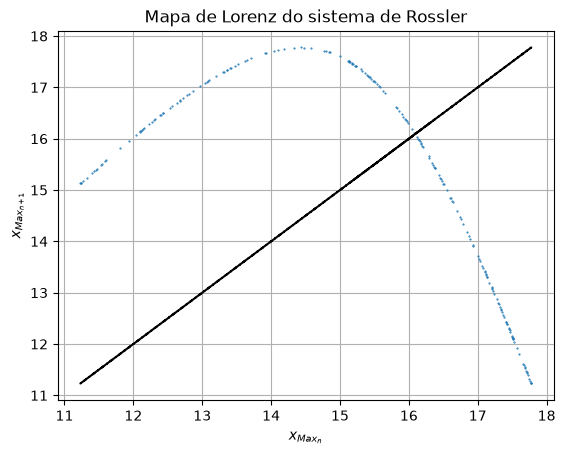

In [5]:
r0 = np.random.randn(3)

tSpan = 3_000 # tempo maior, para melhor visualização do mapa de lorenz. 
# Imagem muito fraca se for usado um tSpan menor, como é feito na maioria dos outros itens


Sol = simularosslerIVP(a =0.1, b=0.1, c=11., tTransiente=1_000, tSpan=3_000, nMax=200, r0=r0, options=options)
xMax = Sol[2].y_events[0][:,0] 



plt.plot( xMax[:-1], xMax[1:], '.', ms=1 )
plt.plot( xMax, xMax, '--k' )
plt.xlabel( r'$x_{Max_{n}}$' )
plt.ylabel( r'$x_{Max_{n+1}}$' )
plt.title('Mapa de Lorenz do sistema de Rossler')
plt.grid()
plt.show()


# b) 

#### Integração e diagrama de bifurcação

In [6]:
# Montagem do diagrama

cI = 2.01 
cF = cI + 18
cStep = 0.005
cs = np.arange(cI,cF+0.5*cStep, cStep) # montando o array dos valores de c, com passo de 0.005


r0 = np.random.randn(3)
tTransiente = 5_000
tSpan = 10_000
nMax = 1_000

paramsCPP = dict(r0=r0, tTransiente=tTransiente, tSpan=tSpan, # Parâmetros da Integração
                 a = 0.1, b = 0.1, # Parâmetros do Sistema
                 varNum="z`", dir=-1, crossVal=0, maxCross=nMax, # Parâmetros dos Eventos
                 rtol=options['rtol'], atol=options['atol']) # Parâmetros do Integrador




t0 = time.time()
j = 0
xMax = []
rEv = []
nCPP = len(cs)
for i, c in enumerate(cs):
    Sol = simulaRosslerCPP(c=c, dense_output=False, trajectory=False, **paramsCPP)
    rEvent = Sol.y_events
    # Printa a cada 20% das integrações
    if 100 * i / nCPP >= j * 20 or i == nCPP-1:
        t2 = time.time()
        print(f"[{j*20}% ({i+1} cs)] c = {c:g} | t = {t2-t0:.3g}s")
        j+=1
    rEv.append(rEvent)
    xMax.append(rEvent[2])
t1 = time.time()
print(f"\nC++ Serial ({len(cs)} cs): {t1-t0:.1f}s\n") # printa o tempo necessário para a integração, assim como vimos para o sistema de Lorenz

#np.savez(f'15489998_{cs[0]:g}', nUSP=15489998, cs=cs, xMax=xMax, rMax=rEv) --> Se quiser salvar o array do diagrama

[0% (1 cs)] c = 2.01 | t = 0.0117s
[20% (722 cs)] c = 5.615 | t = 8.08s
[40% (1442 cs)] c = 9.215 | t = 19s
[60% (2162 cs)] c = 12.815 | t = 34.5s
[80% (2882 cs)] c = 16.415 | t = 48.9s
[100% (3601 cs)] c = 20.01 | t = 64.3s

C++ Serial (3601 cs): 64.3s



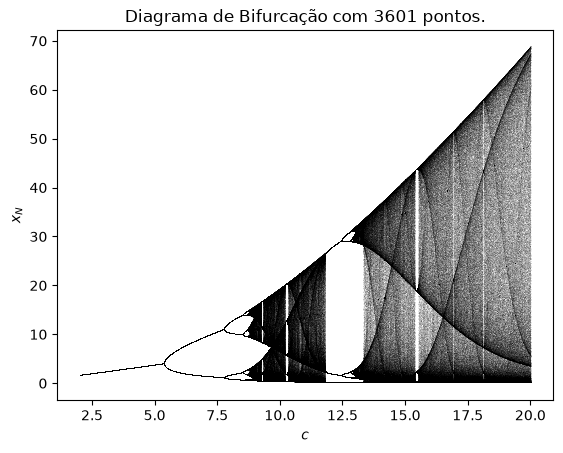

In [ ]:
# Plot do diagrama
plt.close("all")
plt.figure()
for c, xM in zip(cs, xMax):
  plt.plot(c*np.ones_like(xM), xM, ',k', alpha=0.05)
plt.xlabel(r"$c$")
plt.ylabel(f"$x_N$")
plt.title(f"Diagrama de Bifurcação com {len(cs)} pontos.")
plt.show()

# c) 

### Cascata de duplicações e atratores periodicos

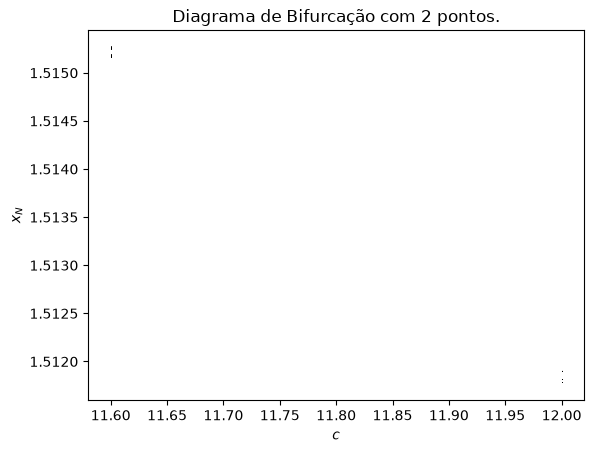

In [10]:
# IMAGEM INTERATIVA
plt.close("all")
plt.figure()
for c, xM in zip(cs, xMax):
  plt.plot(c*np.ones_like(xM), xM, ',k', alpha=0.05)
plt.xlabel(r"$c$")
plt.ylabel(f"$x_N$")
plt.title(f"Diagrama de Bifurcação com {len(cs)} pontos.")
plt.show()

c = 4.5


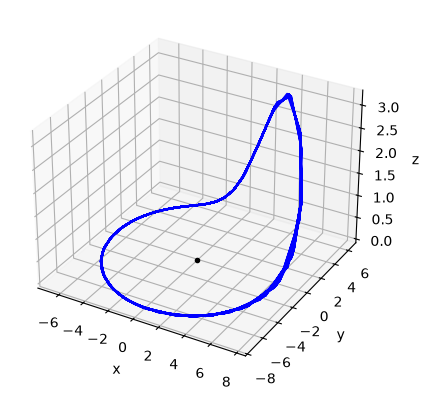

c = 6.5


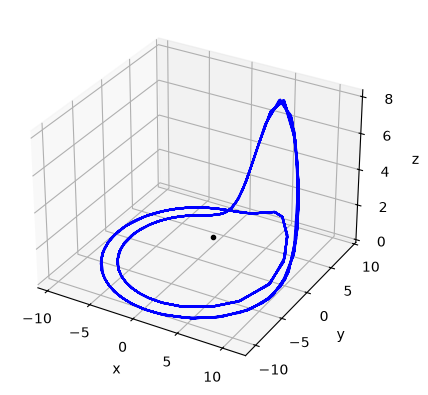

c = 8.0


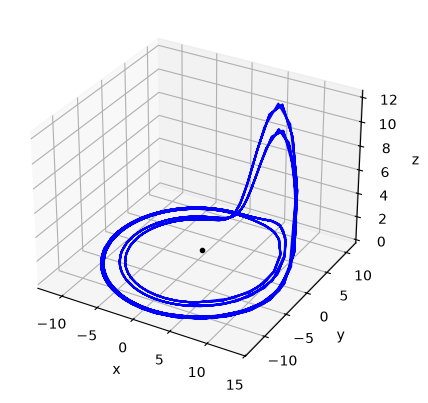

In [7]:
plt.close( 'all' )



NOMEs = ['x', 'y', 'z']

cs = [4.5,6.5,8.0]

for c in cs:

    r0 = np.random.randn(3)
    Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=1_000, tSpan=100, nMax=500, r0=r0, options=options)
    r = Sol[2].y


    print(f'c = {c:.1f}')


    plt.figure()
    ax3d = plt.gcf().add_subplot( projection='3d' )
    ax3d.plot( r[0], r[1], r[2], '-', color = 'blue')
    ax3d.plot( r0[0], r0[1], r0[2], '.k' )
    ax3d.set_xlabel( NOMEs[0] )
    ax3d.set_ylabel( NOMEs[1] )
    ax3d.set_zlabel( NOMEs[2] )
    ax3d.grid()
    plt.show()

c = 4.5


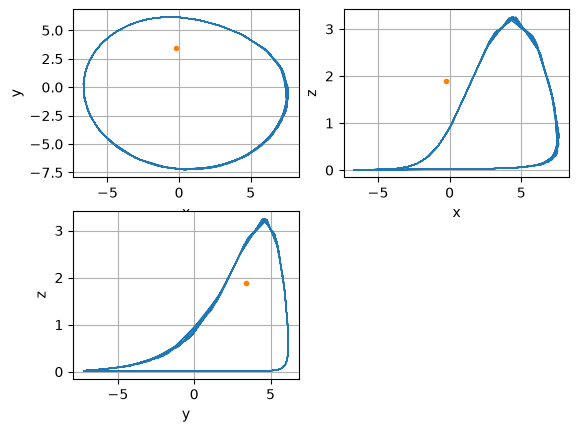

c = 6.5


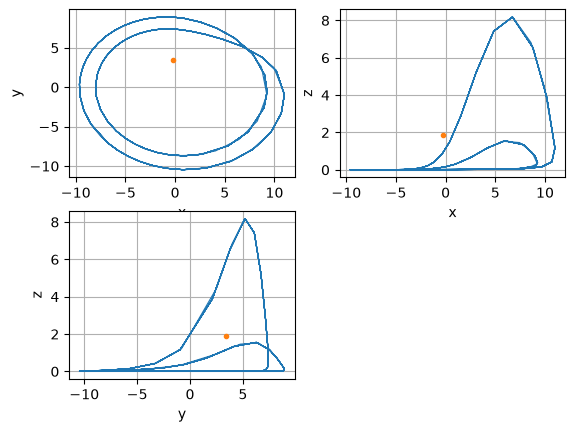

c = 8.0


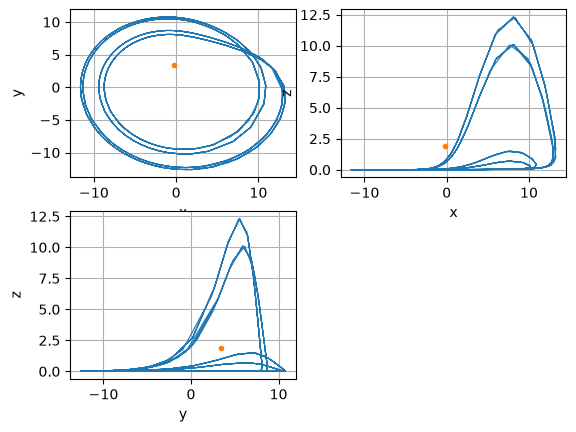

In [ ]:
# para melhor visualização da periodicidade específica, o gráfico xy é bom

r0 = np.random.randn(3)

NOMEs = ['x', 'y', 'z']

# Em tese é 7.5, mas 8.0 mostra bem o período 4
cs = [4.5,6.5,8.0]
for c in cs:
  Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=1_000, tSpan=100, nMax=500, r0=r0, options=options)
  r = Sol[2].y

  print(f'c = {c:.1f}')

  plt.figure()
  i = 0
  for i1 in range(2):
    for i2 in range(i1+1,3):
      i += 1
      plt.subplot(2,2,i)
      plt.plot( r[i1], r[i2], '-', lw=0.8 )
      plt.plot( r0[i1], r0[i2], '.' )
      plt.grid()
      plt.xlabel( NOMEs[i1] )
      plt.ylabel( NOMEs[i2] )
      
  plt.show()

# d) 

####  Janelas periódicas, atrator de período 3 e atratores caóticos próximos da janela

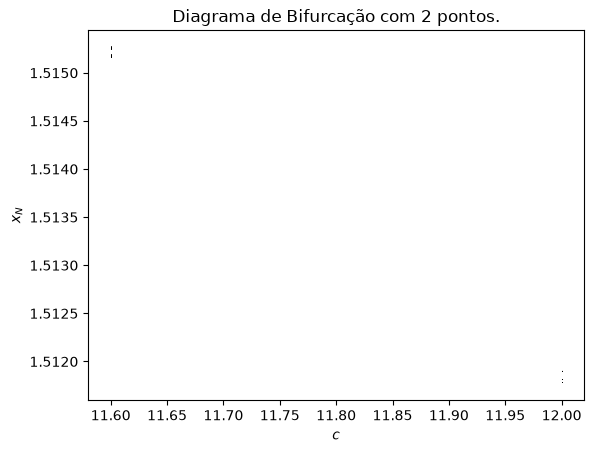

In [11]:
# Imagem interativa - período 3

plt.close("all")
plt.figure()
for c, xM in zip(cs, xMax):
  plt.plot(c*np.ones_like(xM), xM, ',k', alpha=0.05)
plt.xlabel(r"$c$")
plt.ylabel(f"$x_N$")
plt.title(f"Diagrama de Bifurcação com {len(cs)} pontos.")
plt.show()

c = 12.0


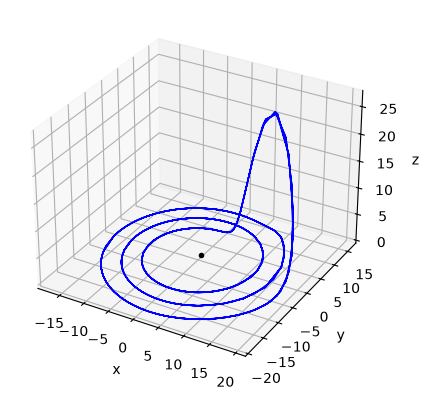

c = 11.8


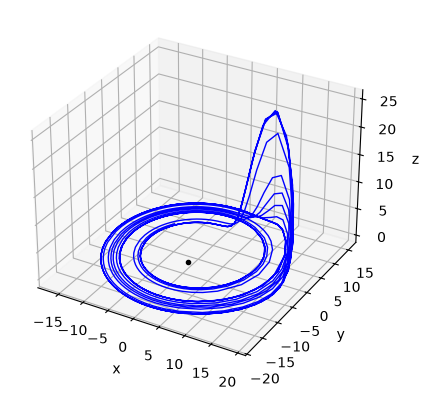

In [16]:
plt.close( 'all' )

NOMEs = ['x', 'y', 'z']

cs = [12., 11.79]

for c in cs:

    r0 = np.random.randn(3)
    Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=1_000, tSpan=100, nMax=500, r0=r0, options=options)
    r = Sol[2].y


    




    

   


    print(f'c = {c:.1f}')


    plt.figure()
    ax3d = plt.gcf().add_subplot( projection='3d' )
    ax3d.plot( r[0], r[1], r[2], '-', lw=1.0, alpha = 1.0, color = 'blue' )
    ax3d.plot( r0[0], r0[1], r0[2], '.k' )
    ax3d.set_xlabel( NOMEs[0] )
    ax3d.set_ylabel( NOMEs[1] )
    ax3d.set_zlabel( NOMEs[2] )
    ax3d.grid()
    plt.show()
    
        


# e)

#### Sensibilidade as condições iniciais e maiores exponentes de Lyapunov

In [ ]:
# menores atol e rtol



c = 4.5


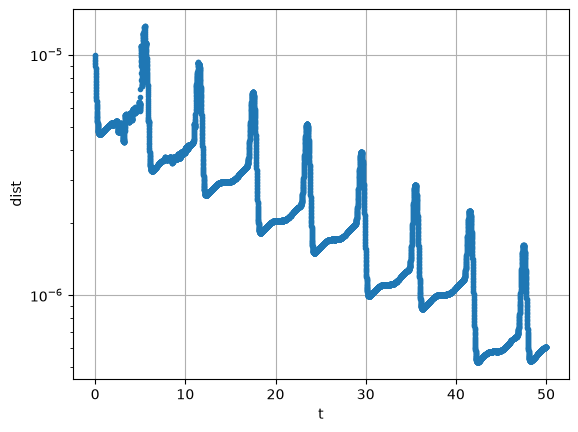

c = 6.5


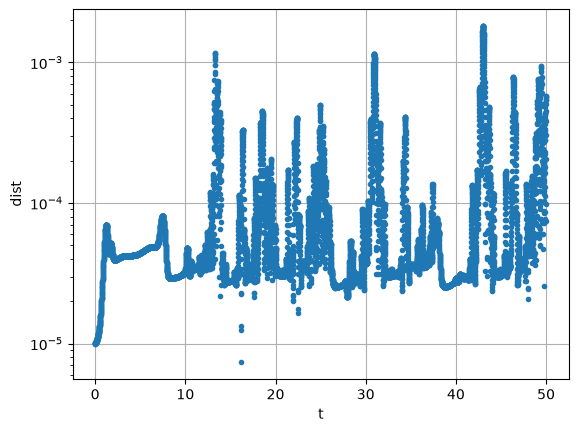

c = 8.0


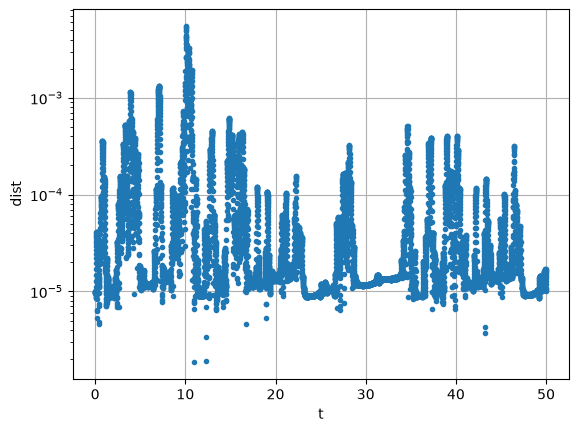

c = 12.0


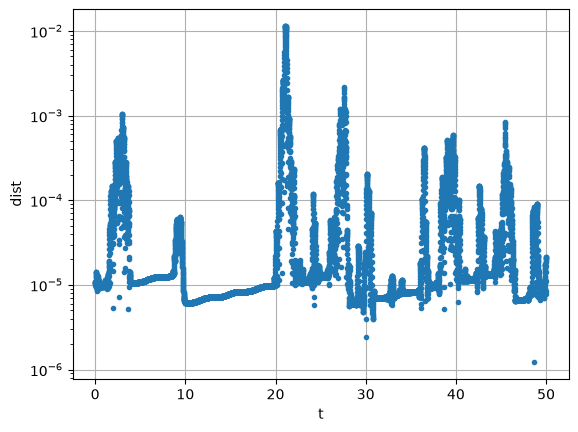

In [ ]:
# Lyapunov nos casos periódicos


OPCOES = dict(  dense_output=True, method = 'DOP853', \
               atol=1e-9, rtol=1e-8 )
r0 = np.random.randn(3)
cs = [4.5,6.5,8.0,12.0]

for c in cs:
    print(f'c = {c:.1f}')

    
    dist0 = 1e-5

    Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=10_000, tSpan=100, nMax=500, r0=r0, options=OPCOES, dist0=dist0)
    r = Sol[2].y
    rlinha = Sol[3].y

    t0, t1 = Sol[2].t, Sol[3].t

    # só o intervalo de tempo que as duas cobrem
    tmin = max(t0[0], t1[0])
    tmax = min(t0[-1], t1[-1])
    t = np.linspace(tmin, tmax, 10_001)

    r      = CubicSpline(t0, r,      axis=1)(t) # Interpolação para termos a mesma quantidade de pontos em r e rlinha
    rlinha = CubicSpline(t1, rlinha, axis=1)(t) # A integração pelo método DOP853 acaba gerando uma quantidade diferente de pontos

    dist = np.sqrt(np.sum((r - rlinha)**2, axis = 0))

    

    
    plt.close( 'all' )
    plt.figure()
    plt.plot( t,dist, '.' )
    plt.xlabel( 't' )
    plt.ylabel( 'dist' )
    plt.yscale( 'log' )
    #plt.xlim( [0, 30] )
    plt.grid()
    plt.show()
    
    
    





lambda_1 ≈ 0.0798


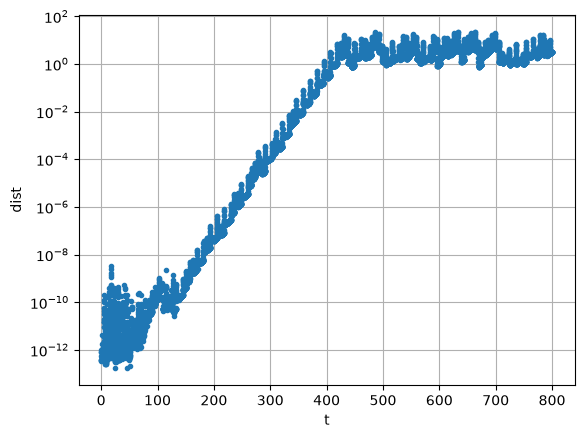

In [36]:
    
    
    OPCOES = dict(dense_output=True, method='DOP853', rtol=3e-14, atol=1e-14)

    Sol = simularosslerIVP(a =0.1, b=0.1, c=11.0, tTransiente=1_000, tSpan=800, nMax=500, r0=r0, options=OPCOES, dist0=1e-12)
    r = Sol[2].y
    rlinha = Sol[3].y

    t0, t1 = Sol[2].t, Sol[3].t

    # só o intervalo de tempo que as duas cobrem
    tmin = max(t0[0], t1[0])
    tmax = min(t0[-1], t1[-1])
    t = np.linspace(tmin, tmax, 10_001)

    r      = CubicSpline(t0, r,      axis=1)(t)
    rlinha = CubicSpline(t1, rlinha, axis=1)(t)

    dist = np.sqrt(np.sum((r - rlinha)**2, axis = 0))

    
    mask = (dist > 1e-8) & (dist < 1e-1)
    coef = np.polyfit(t[mask], np.log(dist[mask]), 1)
    lambda_1 = coef[0]
    print(f'lambda_1 ≈ {lambda_1:.4f}')
    
    plt.close( 'all' )
    plt.figure()
    plt.plot( t,dist, '.' )
    plt.xlabel( 't' )
    plt.ylabel( 'dist' )
    plt.yscale( 'log' )
    #plt.xlim( [0, 30] )
    plt.grid()
    plt.show()


## Outras partes da atividade assíncrona

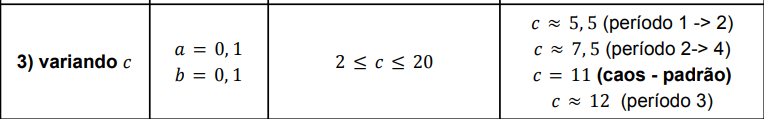

# a)

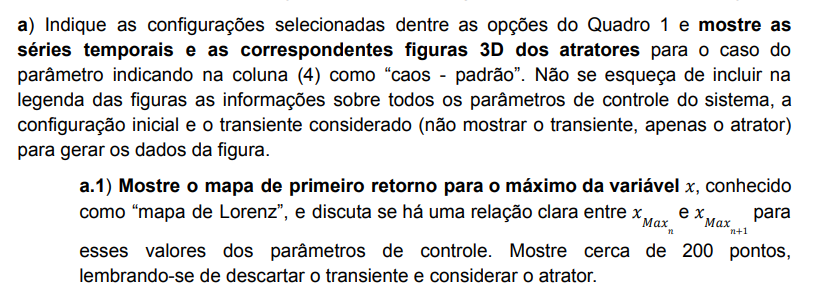

c = 11.0


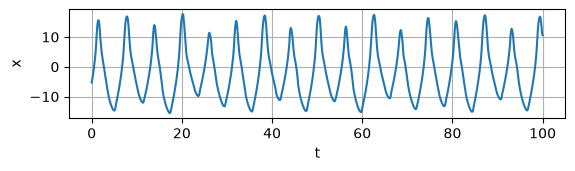

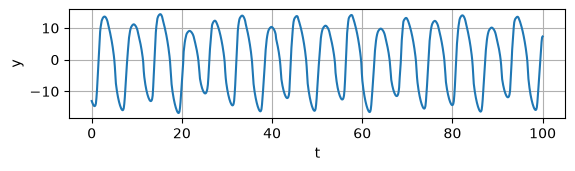

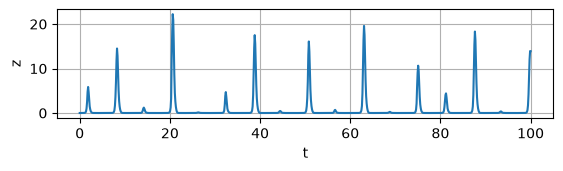

In [103]:
r0 = np.random.randn(3)
NOMEs = ['x', 'y', 'z']
t_span = [0,100]
c = 11.0


Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=1_000, tSpan=100, nMax=500, r0=r0, options=options)
r = Sol[2].y

print(f'c = {c:.1f}')

t = np.linspace( 0, t_span[-1], r.shape[1])

for i in range(3):
  plt.figure()
  plt.subplot(3,1,i+1)
  plt.plot( t, r[i] )
  plt.grid()
  plt.ylabel( NOMEs[i] )
  plt.xlabel( 't' )
  plt.show()

c = 4.5


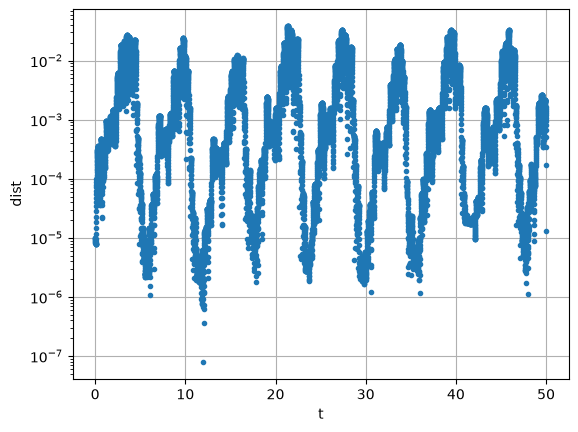

c = 6.5


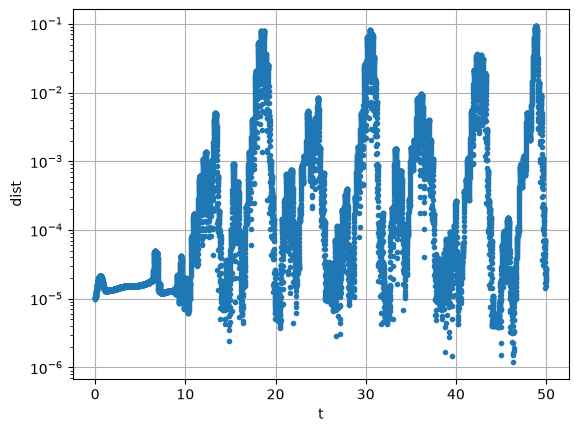

c = 8.0


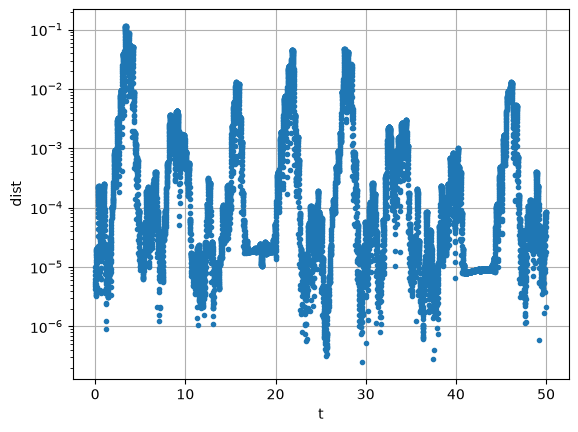

c = 12.0


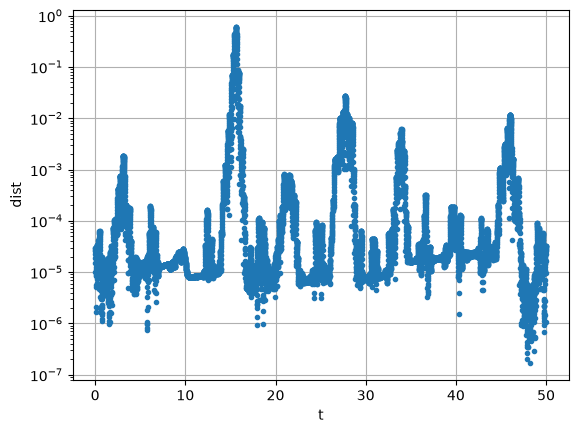

In [62]:
r0 = np.random.randn(3)

cs = [4.5,6.5,8.0,12.0]

for c in cs:
    print(f'c = {c:.1f}')

    
    dist0 = 1e-5

    Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=10_000, tSpan=50, nMax=500, r0=r0, options=OPCOES, dist0=dist0)
    r = Sol[2].y
    rlinha = Sol[3].y

    t0, t1 = Sol[2].t, Sol[3].t

    # só o intervalo de tempo que as duas cobrem
    tmin = max(t0[0], t1[0])
    tmax = min(t0[-1], t1[-1])
    t = np.linspace(tmin, tmax, 10_001)

    r      = CubicSpline(t0, r,      axis=1)(t)
    rlinha = CubicSpline(t1, rlinha, axis=1)(t)

    dist = np.sqrt(np.sum((r - rlinha)**2, axis = 0))

    

    
    plt.close( 'all' )
    plt.figure()
    plt.plot( t,dist, '.' )
    plt.xlabel( 't' )
    plt.ylabel( 'dist' )
    plt.yscale( 'log' )
    #plt.xlim( [0, 30] )
    plt.grid()
    plt.show()
    
    
    





lambda_1 ≈ 0.0626


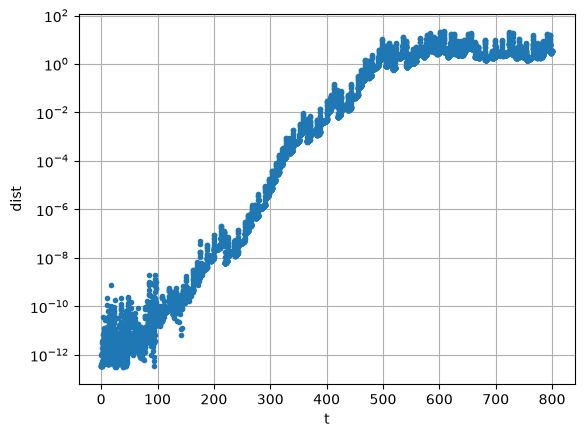

In [ ]:
    
    
    OPCOES = dict(dense_output=True, method='DOP853', rtol=3e-14, atol=1e-14)

    Sol = simularosslerIVP(a =0.1, b=0.1, c=11.0, tTransiente=1_000, tSpan=800, nMax=500, r0=r0, options=OPCOES, dist0=1e-12)
    r = Sol[2].y
    rlinha = Sol[3].y

    t0, t1 = Sol[2].t, Sol[3].t

    # só o intervalo de tempo que as duas cobrem
    tmin = max(t0[0], t1[0])
    tmax = min(t0[-1], t1[-1])
    t = np.linspace(tmin, tmax, 10_001)

    r      = CubicSpline(t0, r,      axis=1)(t)
    rlinha = CubicSpline(t1, rlinha, axis=1)(t)

    dist = np.sqrt(np.sum((r - rlinha)**2, axis = 0))

    
    mask = (dist > 1e-10) & (dist < 1e+0)
    coef = np.polyfit(t[mask], np.log(dist[mask]), 1)
    lambda_1 = coef[0]
    print(f'lambda_1 ≈ {lambda_1:.4f}')
    
    plt.close( 'all' )
    plt.figure()
    plt.plot( t,dist, '.' )
    plt.xlabel( 't' )
    plt.ylabel( 'dist' )
    plt.yscale( 'log' )
    #plt.xlim( [0, 30] )
    plt.grid()
    plt.show()

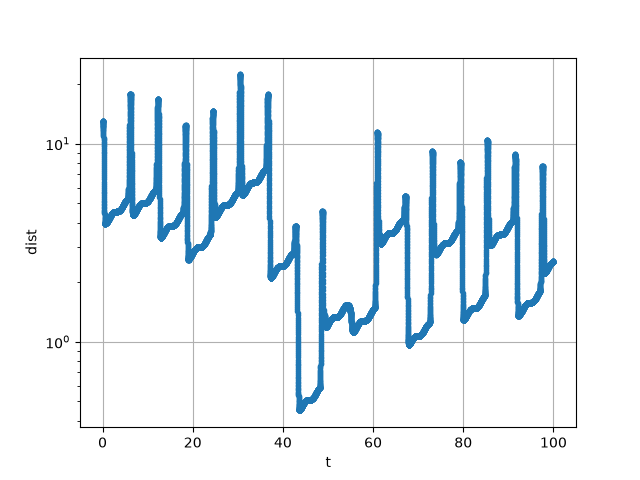

In [100]:

plt.close( 'all' )
plt.figure()
plt.plot( t, d, '.' )
plt.xlabel( 't' )
plt.ylabel( 'dist' )
plt.yscale( 'log' )
#plt.xlim( [0, 30] )
plt.grid()
plt.show()